# receptive_field_scope: seeing the receptive field

This notebook measures receptive fields of three small *untrained* image encoders and draws them as heatmaps over an image,
then does the same for a waveform. Swap in your own trained model where marked.

* **heat** = |d output / d input| (log scale, 6 decades) for one output token
* **dashed cyan box** = *support*: every input pixel with non-negligible gradient (tiling-safe bound)
* **white circle** = *effective* radius: holds 95% of the gradient mass
* **white +** = the probed output token's centre

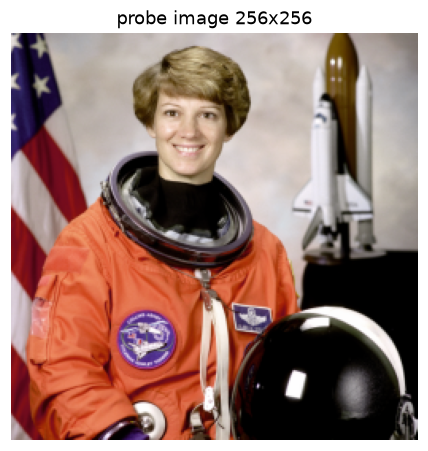

In [2]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from skimage import data, transform
from receptive_field_scope import (measure_receptive_field, sweep_centers, summarize, activate_gates,
                                   layerwise_receptive_field, print_layerwise, margin_sweep, print_margin_sweep, over_images)
from receptive_field_scope.plotting import overlay_heatmap, plot_waveform_rf
torch.manual_seed(0)
plt.rcParams['figure.dpi'] = 110

def to_tensor(img, size=256):
    img = transform.resize(img, (size, size), anti_aliasing=True)           # float in [0,1]
    return torch.tensor(img, dtype=torch.float32).permute(2, 0, 1)[None]    # [1, 3, H, W]

astronaut = to_tensor(data.astronaut())
coffee    = to_tensor(data.coffee())
chelsea   = to_tensor(data.chelsea())
image = astronaut
plt.imshow(image[0].permute(1, 2, 0)); plt.axis('off'); plt.title('probe image 256x256');

## Three toy tokenizers (patch size 8 -> 32x32 tokens)

1. **local conv**: stem conv + patchify + 5 token-space 3x3 convs (exact structural support = 90 px).
2. **blocked mixing + zero-init gate**: like haloed local attention (mean-pool stand-in), reach depends on position inside a 4x4-token block.
3. **global attention**: one multi-head attention layer over all tokens (no positional encoding, so it looks the same from everywhere).

In [ ]:
class LocalConv(nn.Module):
    def __init__(self, hops=5, dim=32):
        super().__init__()
        self.stem = nn.Conv2d(3, 16, 3, padding=1)
        self.pat = nn.Conv2d(16, dim, 8, stride=8)
        self.body = nn.Sequential(*[nn.Sequential(nn.Conv2d(dim, dim, 3, padding=1), nn.GELU()) for _ in range(hops)])
    def forward(self, x): return self.body(self.pat(self.stem(x)))

class BlockedMix(nn.Module):
    '''Each token mixes in the mean of its own b x b block + a halo (stand-in for haloed local attention).'''
    def __init__(self, b=4, halo=1, dim=32):
        super().__init__(); self.b, self.h = b, halo
        self.v = nn.Conv2d(dim, dim, 1); self.gate = nn.Parameter(torch.zeros(1))
    def forward(self, x):
        B, C, H, W = x.shape; b, h = self.b, self.h
        xp = nn.functional.pad(x, (h, h, h, h)); ctx = torch.zeros_like(x)
        for by in range(0, H, b):
            for bx in range(0, W, b):
                ctx[:, :, by:by+b, bx:bx+b] = xp[:, :, by:by+b+2*h, bx:bx+b+2*h].mean((2, 3), keepdim=True)
        return x + self.gate * self.v(ctx)

class Blocked(nn.Module):
    def __init__(self):
        super().__init__(); self.base = LocalConv(hops=2); self.mix = BlockedMix()
    def forward(self, x): return self.mix(self.base(x))

class GlobalAttn(nn.Module):
    def __init__(self, dim=32):
        super().__init__(); self.base = LocalConv(hops=2, dim=dim)
        self.attn = nn.MultiheadAttention(dim, 4, batch_first=True)
    def forward(self, x):
        z = self.base(x); B, C, H, W = z.shape
        t = z.flatten(2).transpose(1, 2)
        t = t + self.attn(t, t, t)[0]
        return t.transpose(1, 2).reshape(B, C, H, W)

local_enc, blocked_enc, global_enc = LocalConv().eval(), Blocked().eval(), GlobalAttn().eval()

## 1. One token, one heatmap

Centre token of the 32x32 grid. `keep_maps=True` keeps the sensitivity map for plotting.

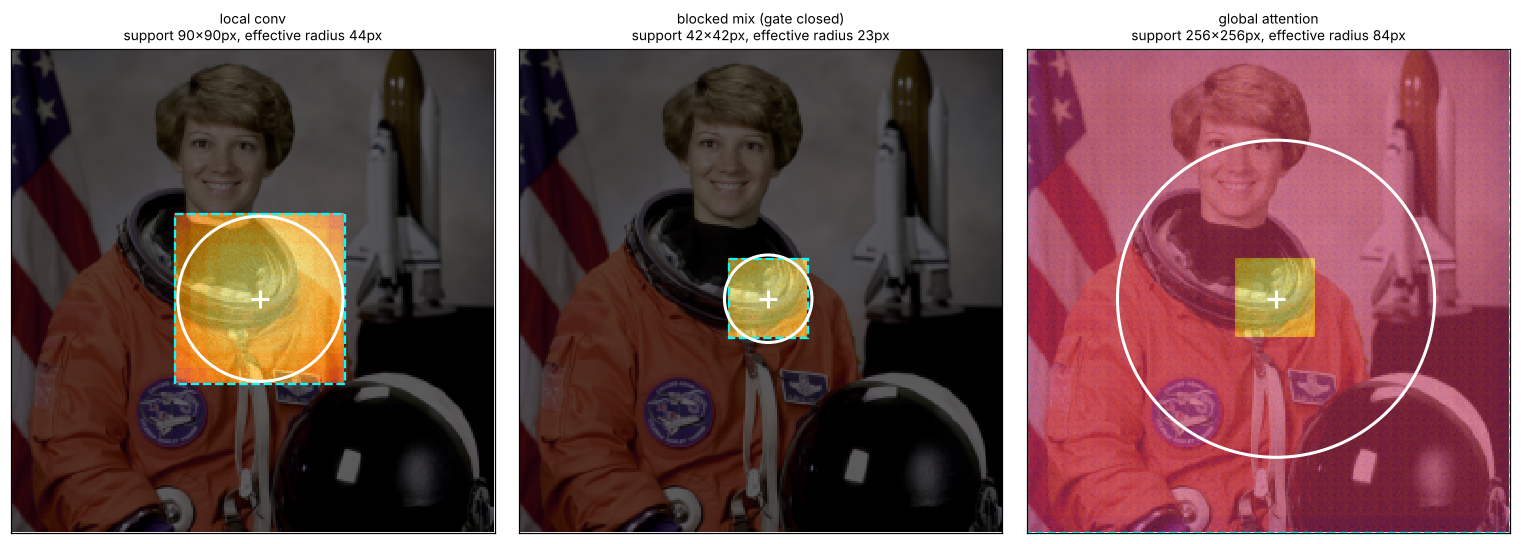

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, (name, m) in zip(axes, [("local conv", local_enc), ("blocked mix (gate closed)", blocked_enc), ("global attention", global_enc)]):
    r = measure_receptive_field(m, input=image, keep_maps=True)[0]
    overlay_heatmap(image, r, ax=ax, title=f"{name}\nsupport {r.width[0]:.0f}x{r.width[1]:.0f}px, effective radius {r.eff_radius:.0f}px")
plt.tight_layout();

Notes: the *gate-closed* blocked model sees almost nothing beyond its own token (the attention-like branch contributes zero gradient until the gate opens).
Next we open the gate, and look at how the reach changes with where the token sits inside its 4x4 block.

## 2. Alignment: reach depends on the position inside a block

`sweep_centers(out_shape, period=4)` enumerates the 16 token offsets of one block; here are four of them (gates opened).

== blocked mix, gates open (16 centres) ==
  support radius    min      45.0   max      53.0
  y lo              min      29.0   max      53.0
  y hi              min      29.0   max      53.0
  x lo              min      29.0   max      53.0
  x hi              min      29.0   max      53.0
  effective radius  min      30.8   max      37.5


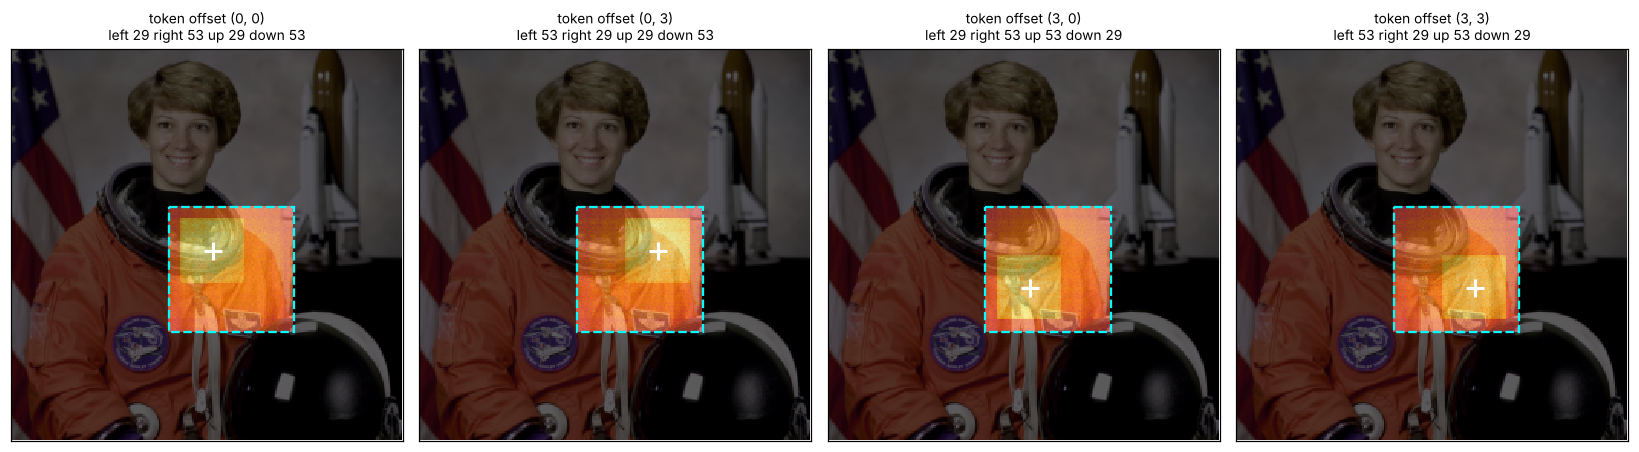

In [ ]:
with activate_gates(blocked_enc, 1.0):
    cs = sweep_centers((32, 32), period=4)
    results = measure_receptive_field(blocked_enc, input=image, centers=cs, keep_maps=True)
    picks = [0, 3, 12, 15]                                    # the four corners of the 4x4 block
    fig, axes = plt.subplots(1, 4, figsize=(15, 4))
    for ax, i in zip(axes, picks):
        r = results[i]
        overlay_heatmap(image, r, ax=ax, show_effective=False,
                        title=f"token offset {tuple(c % 4 for c in r.center)}\nleft {r.left:.0f} right {r.right:.0f} up {r.up:.0f} down {r.down:.0f}")
    plt.tight_layout()
    summarize(results, "blocked mix, gates open")

Tokens at the left/top edge of a block reach far to the right/bottom and little to the left/up (and vice versa).
Tile margins must cover the *worst* offset, and tiles should be multiples of the block size so every tile sees the same alignment.

## 3. How much does the effective field depend on the image?

A global-attention model's effective field is data dependent; a conv model's support is not. `over_images` repeats the measurement on several inputs.

global attn  effective radius mean 84.3 +- 0.3 px   support mean 132.0 +- 0.0 px
local conv   effective radius mean 43.7 +- 0.0 px   support mean 45.0 +- 0.0 px


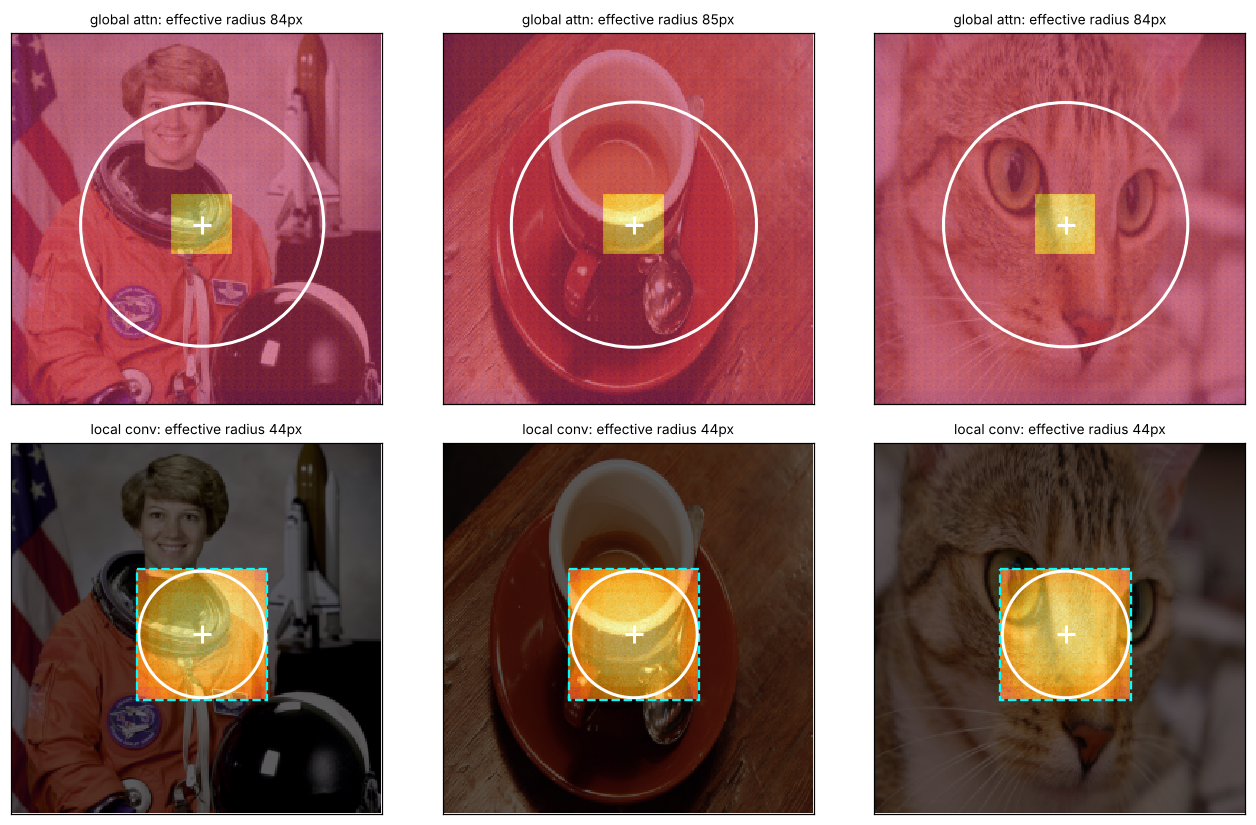

In [ ]:
imgs = [astronaut, coffee, chelsea]
fig, axes = plt.subplots(2, 3, figsize=(12, 7.6))
for j, im in enumerate(imgs):
    r = measure_receptive_field(global_enc, input=im, keep_maps=True)[0]
    overlay_heatmap(im, r, ax=axes[0, j], show_support=False, title=f"global attn: effective radius {r.eff_radius:.0f}px")
    r = measure_receptive_field(local_enc, input=im, keep_maps=True)[0]
    overlay_heatmap(im, r, ax=axes[1, j], title=f"local conv: effective radius {r.eff_radius:.0f}px")
plt.tight_layout()
for name, m in [("global attn", global_enc), ("local conv", local_enc)]:
    o = over_images(m, imgs)
    print(f"{name:12s} effective radius mean {o['eff_mean']:.1f} +- {o['eff_std']:.1f} px   support mean {o['support_mean']:.1f} +- {o['support_std']:.1f} px")

## 4. Where does the reach come from? (per-layer hops)

In [ ]:
print_layerwise(layerwise_receptive_field(local_enc.body, (1, 32, 32, 32),
                                          predicate=lambda n, m: isinstance(m, nn.Conv2d)))
print()
print("whole encoder, in input pixels:")
print_layerwise(layerwise_receptive_field(local_enc, (1, 3, 256, 256)))

module                                out        lo        hi   radius     hop     eff
0.0                              (32, 32)       2,2       2,2      1.5     1.5     1.4
1.0                              (32, 32)       2,2       2,2      2.5     1.0     2.8
2.0                              (32, 32)       4,4       4,4      3.5     1.0     3.6
3.0                              (32, 32)       4,4       4,4      4.5     1.0     4.5
4.0                              (32, 32)       6,6       6,6      5.5     1.0     5.1

whole encoder, in input pixels:
module                                out        lo        hi   radius     hop     eff
stem                           (256, 256)       2,2       2,2      1.5     1.5     1.4
pat                              (32, 32)       5,5       5,5      5.0     3.5     5.7
body                             (32, 32)     45,45     45,45     45.0    40.0    43.7


## 5. The practical question: which tile margin reproduces the full-image encode?

In [ ]:
rows = margin_sweep(local_enc, [image], tile=64, margins=[0, 16, 32, 48, 64])
print_margin_sweep(rows)

    margin  frac differing    max |err|
         0        0.684509    1.172e-02
        16        0.205139    6.870e-04
        32        0.003723    1.677e-04
        48        0.000000    1.490e-08
        64        0.000000    1.490e-08


One-sided reach of the local model is ~45 px, so a margin of 48 px (a multiple of the patch size 8) reproduces the full encode up to float noise.
For your own model use the *support* number (or measure with `margin_sweep`), not the effective radius: tail influence that is 3% of the energy can still flip a latent bit.

## 6. Audio: a wav2vec2/HuBERT-style conv extractor on a waveform

support width 400 samples = 25.0 ms (theory: 400 samples = 25 ms)


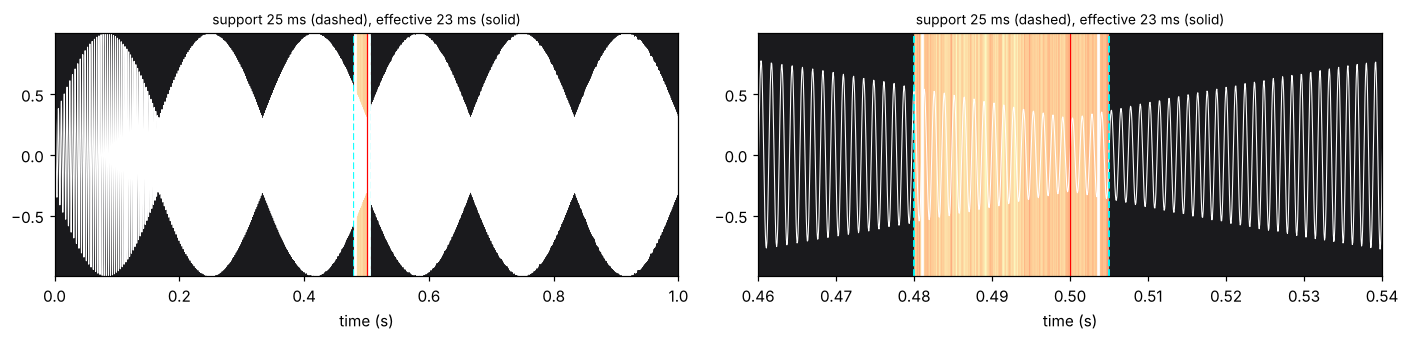

In [ ]:
KERNELS, STRIDES = (10, 3, 3, 3, 3, 2, 2), (5, 2, 2, 2, 2, 2, 2)
def extractor(width=16):
    layers, cin = [], 1
    for k, s in zip(KERNELS, STRIDES):
        layers += [nn.Conv1d(cin, width, k, stride=s, bias=False), nn.GELU()]; cin = width
    return nn.Sequential(*layers).eval()

SR = 16000
t = torch.arange(SR) / SR
wave = (torch.sin(2*np.pi*(200 + 600*t)*t) * (0.3 + 0.7*torch.sin(2*np.pi*3*t).abs())).float()[None, None]   # 1 s chirp
r = measure_receptive_field(extractor(), input=wave, keep_maps=True, eps=1e-12)[0]
print(f"support width {r.width[0]:.0f} samples = {r.width[0]*1000/SR:.1f} ms (theory: 400 samples = 25 ms)")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
plot_waveform_rf(wave, r, SR, ax=axes[0])
c0 = r.ref[0] / SR
plot_waveform_rf(wave, r, SR, ax=axes[1], xlim=(c0 - 0.04, c0 + 0.04))     # zoom: +-40 ms around the frame
plt.tight_layout();

The conv extractor's reach is exactly 400 samples (25 ms); frames are 320 samples (20 ms) apart. In the real HuBERT/wav2vec2 stack the transformer on top is global, and
the base-size feature extractor's first-layer GroupNorm over time makes even the *conv* part globally dependent (weakly). See `examples/hubert_receptive_field.py`.

## Using your own model

```python
model = MyAutoencoder.load(...).eval()
enc = model.encoder                                    # any callable [1,C,H,W] -> [1,C',h,w]
r = measure_receptive_field(enc, input=image, centers=sweep_centers((h, w), period=block), keep_maps=True)
overlay_heatmap(image, r[0])
```
Models returning `[B, T, C]` need `channels_last(fn)`; zero-init gates need `with activate_gates(model): ...` to show the structural reach.